# Q2: Indore (IMC), Total vs Non-residential Building Volume Change, 1990–2020

**Course:** Urban Informatics and Spatial Analytics (HS524M), Test 2
**Student:** Manish Chouhan (CE25M108), M.Tech EWRE, IIT Tirupati

**Task:** Using the JRC GHSL built-up volume product (`JRC/GHSL/P2023A/GHS_BUILT_V`) in Google Earth Engine, compare the change in *total* (`built_volume_total`) and *non-residential* (`built_volume_nres`) building volume for Indore over 1990–2020 (5-year epochs).

**Data sources**
- Building volume: JRC GHSL GHS-BUILT-V R2023A (Pesaresi & Politis, 2023), 100 m grid
- City boundary: Indore Municipal Corporation polygon from Swachh Bharat Mission ULB boundaries via [ramSeraph/indian_admin_boundaries](https://github.com/ramSeraph/indian_admin_boundaries/releases/tag/urban) (CC0 1.0)

**Workflow:** connect to Earth Engine → load boundary → extract volumes per epoch → summary statistics → maps with fixed colour scale → time-lapse GIF → comparison charts → web page.

## Step 1: Install packages and connect to Google Earth Engine
Install the required libraries, authenticate, and initialise Earth Engine with the project ID.

In [3]:
%pip install earthengine-api geemap py7zr geopandas

Note: you may need to restart the kernel to use updated packages.


In [19]:
import ee

ee.Initialize(project="utility-braid-489911-m7")
print("GEE connected")

GEE connected


## Step 2: Check the GHSL dataset
List the available epochs (1975–2030) and bands in `JRC/GHSL/P2023A/GHS_BUILT_V`. Bands used: `built_volume_total` and `built_volume_nres` (m³ per 100 m cell).

In [20]:
col = ee.ImageCollection("JRC/GHSL/P2023A/GHS_BUILT_V")
print("Epoch ids:", col.aggregate_array("system:index").getInfo())
print("Bands:", col.first().bandNames().getInfo())

Epoch ids: ['1975', '1980', '1985', '1990', '1995', '2000', '2005', '2010', '2015', '2020', '2025', '2030']
Bands: ['built_volume_total', 'built_volume_nres']


## Step 3: Load urban boundaries and find Indore
Extract the Swachh Bharat Mission ULB boundary file, read it with GeoPandas, and search for Indore records.

In [21]:
import py7zr, os, glob
import geopandas as gpd

src = r"SBM_ULBs.geojsonl.7z"   # <-- apna path
os.makedirs("boundary_data", exist_ok=True)
with py7zr.SevenZipFile(src, mode="r") as z:
    z.extractall(path="boundary_data")

f = glob.glob("boundary_data/**/*.geojsonl", recursive=True)[0]
ulbs = gpd.read_file(f)
print(ulbs.shape)
print(ulbs.columns.tolist())

mask = ulbs.apply(lambda c: c.astype(str).str.contains("indore", case=False, na=False)).any(axis=1)
indore_candidates = ulbs[mask]
print(indore_candidates.drop(columns="geometry"))

(3373, 11)
['objectid', 'stnm', 'stcode', 'distnm', 'distcode', 'ulbnm', 'ulbcode', 'remark', 'st_area(shape)', 'st_perimeter(shape)', 'geometry']
      objectid stnm stcode    distnm distcode             ulbnm ulbcode  \
1046     11487          23  INDORE\n      439               RAU  802274   
1307     13389          23    INDORE      439      INDORE (IMC)  802273   
1875     23015          23  INDORE\n      439  RUNJI-GAUTAMPURA  802268   
1889     23029          23    INDORE      439             SAWER  802272   
2165     39845          23  INDORE\n      439             BETMA  802270   
2222     45040          23    INDORE      439            HATHOD  802271   
2955     95114          23    INDORE      439        MHOW CANTT  802275   

                  remark  st_area(shape)  st_perimeter(shape)  
1046                  Ok        0.000696             0.198926  
1307    Imc ULB Boundary        0.024590             1.057744  
1875                  Ok        0.000329             0.11307

## Step 4: Select the Indore Municipal Corporation (IMC) boundary
Out of the Indore-district ULBs, `INDORE (IMC)` (ulbcode 802273) is the city boundary. Reproject to EPSG:4326, check area (~280 km²) and save as GeoJSON.

In [22]:
indore = ulbs[ulbs["ulbcode"].astype(str) == "802273"].copy().to_crs(4326)
print(indore[["objectid", "ulbnm", "ulbcode", "remark"]])
print("Geometry type:", indore.geometry.iloc[0].geom_type)
print("Area (km2):", round(indore.to_crs(32643).area.iloc[0] / 1e6, 1))
print("Bounds:", indore.total_bounds)

indore.to_file("indore_imc_boundary.geojson", driver="GeoJSON")

      objectid         ulbnm ulbcode            remark
1307     13389  INDORE (IMC)  802273  Imc ULB Boundary
Geometry type: Polygon
Area (km2): 279.6
Bounds: [75.7685348 22.6241644 75.9910318 22.8219986]


## Step 5: Send the boundary to Earth Engine
Convert the polygon to an Earth Engine geometry and verify its area against the GeoPandas result.

In [23]:
roi_geom = ee.Geometry(indore.geometry.iloc[0].__geo_interface__, None, False)
roi = ee.FeatureCollection([ee.Feature(roi_geom, {"name": "Indore (IMC)"})])
print("ROI area (km2) from GEE:", round(roi_geom.area(1).divide(1e6).getInfo(), 1))

ROI area (km2) from GEE: 280.4


## Step 6: Extract total and non-residential building volume (1990–2020)
For each 5-year epoch, sum the 100 m cell values inside the boundary. Compute residential volume (total − non-residential), non-residential share, and % change relative to 1990. Results are in million m³ (Mm³) and saved as CSV.

In [24]:
import pandas as pd

col = ee.ImageCollection("JRC/GHSL/P2023A/GHS_BUILT_V")
years = [1990, 1995, 2000, 2005, 2010, 2015, 2020]

rows = []
for y in years:
    img = col.filter(ee.Filter.eq("system:index", str(y))).first()
    s = img.select(["built_volume_total", "built_volume_nres"]).reduceRegion(
        reducer=ee.Reducer.sum(),
        geometry=roi_geom,
        scale=100,
        maxPixels=1e13
    ).getInfo()
    rows.append({"year": y,
                 "total_m3": s["built_volume_total"],
                 "nres_m3": s["built_volume_nres"]})

stats = pd.DataFrame(rows)
stats["res_m3"]        = stats["total_m3"] - stats["nres_m3"]
stats["total_Mm3"]     = stats["total_m3"] / 1e6
stats["nres_Mm3"]      = stats["nres_m3"] / 1e6
stats["res_Mm3"]       = stats["res_m3"] / 1e6
stats["nres_share_%"]  = 100 * stats["nres_m3"] / stats["total_m3"]
stats["total_chg_%_vs_1990"] = 100 * (stats["total_m3"] / stats.loc[0, "total_m3"] - 1)
stats["nres_chg_%_vs_1990"]  = 100 * (stats["nres_m3"]  / stats.loc[0, "nres_m3"]  - 1)

print(stats[["year", "total_Mm3", "nres_Mm3", "res_Mm3", "nres_share_%",
             "total_chg_%_vs_1990", "nres_chg_%_vs_1990"]].round(2).to_string(index=False))
stats.to_csv("indore_ghsl_stats.csv", index=False)

 year  total_Mm3  nres_Mm3  res_Mm3  nres_share_%  total_chg_%_vs_1990  nres_chg_%_vs_1990
 1990     241.56     17.09   224.47          7.08                 0.00                0.00
 1995     297.90     20.90   277.00          7.02                23.33               22.29
 2000     360.82     24.94   335.88          6.91                49.37               45.92
 2005     381.31     25.44   355.87          6.67                57.85               48.86
 2010     406.31     25.99   380.32          6.40                68.20               52.06
 2015     430.52     26.56   403.96          6.17                78.22               55.41
 2020     441.35     26.83   414.52          6.08                82.71               56.98


## Step 7: Fix a consistent colour scale
Use the 99th percentile of the 2020 values to set one fixed maximum for each band, so that colours are comparable across all years.

In [25]:
import math, io, requests
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.cm import ScalarMappable
from PIL import Image

img2020 = col.filter(ee.Filter.eq("system:index", "2020")).first()
valid = img2020.select("built_volume_total").gt(0)
p99 = (img2020.select(["built_volume_total", "built_volume_nres"])
       .updateMask(valid)
       .reduceRegion(reducer=ee.Reducer.percentile([99]), geometry=roi_geom,
                     scale=100, maxPixels=1e13).getInfo())
print(p99)

VMAX_TOTAL = max(int(math.ceil(p99["built_volume_total"] / 10000.0) * 10000), 10000)
VMAX_NRES  = max(int(math.ceil(p99["built_volume_nres"]  / 5000.0)  * 5000), 5000)
print("VMAX_TOTAL:", VMAX_TOTAL, "| VMAX_NRES:", VMAX_NRES)

{'built_volume_nres': 36262.4754601227, 'built_volume_total': 74235.77777777778}
VMAX_TOTAL: 80000 | VMAX_NRES: 40000


## Step 8: Thematic maps, 1990–2020
2 × 7 panel: top row = total built volume, bottom row = non-residential built volume. Includes title, legend with units (m³ per 100 m cell), city boundary, and data sources.

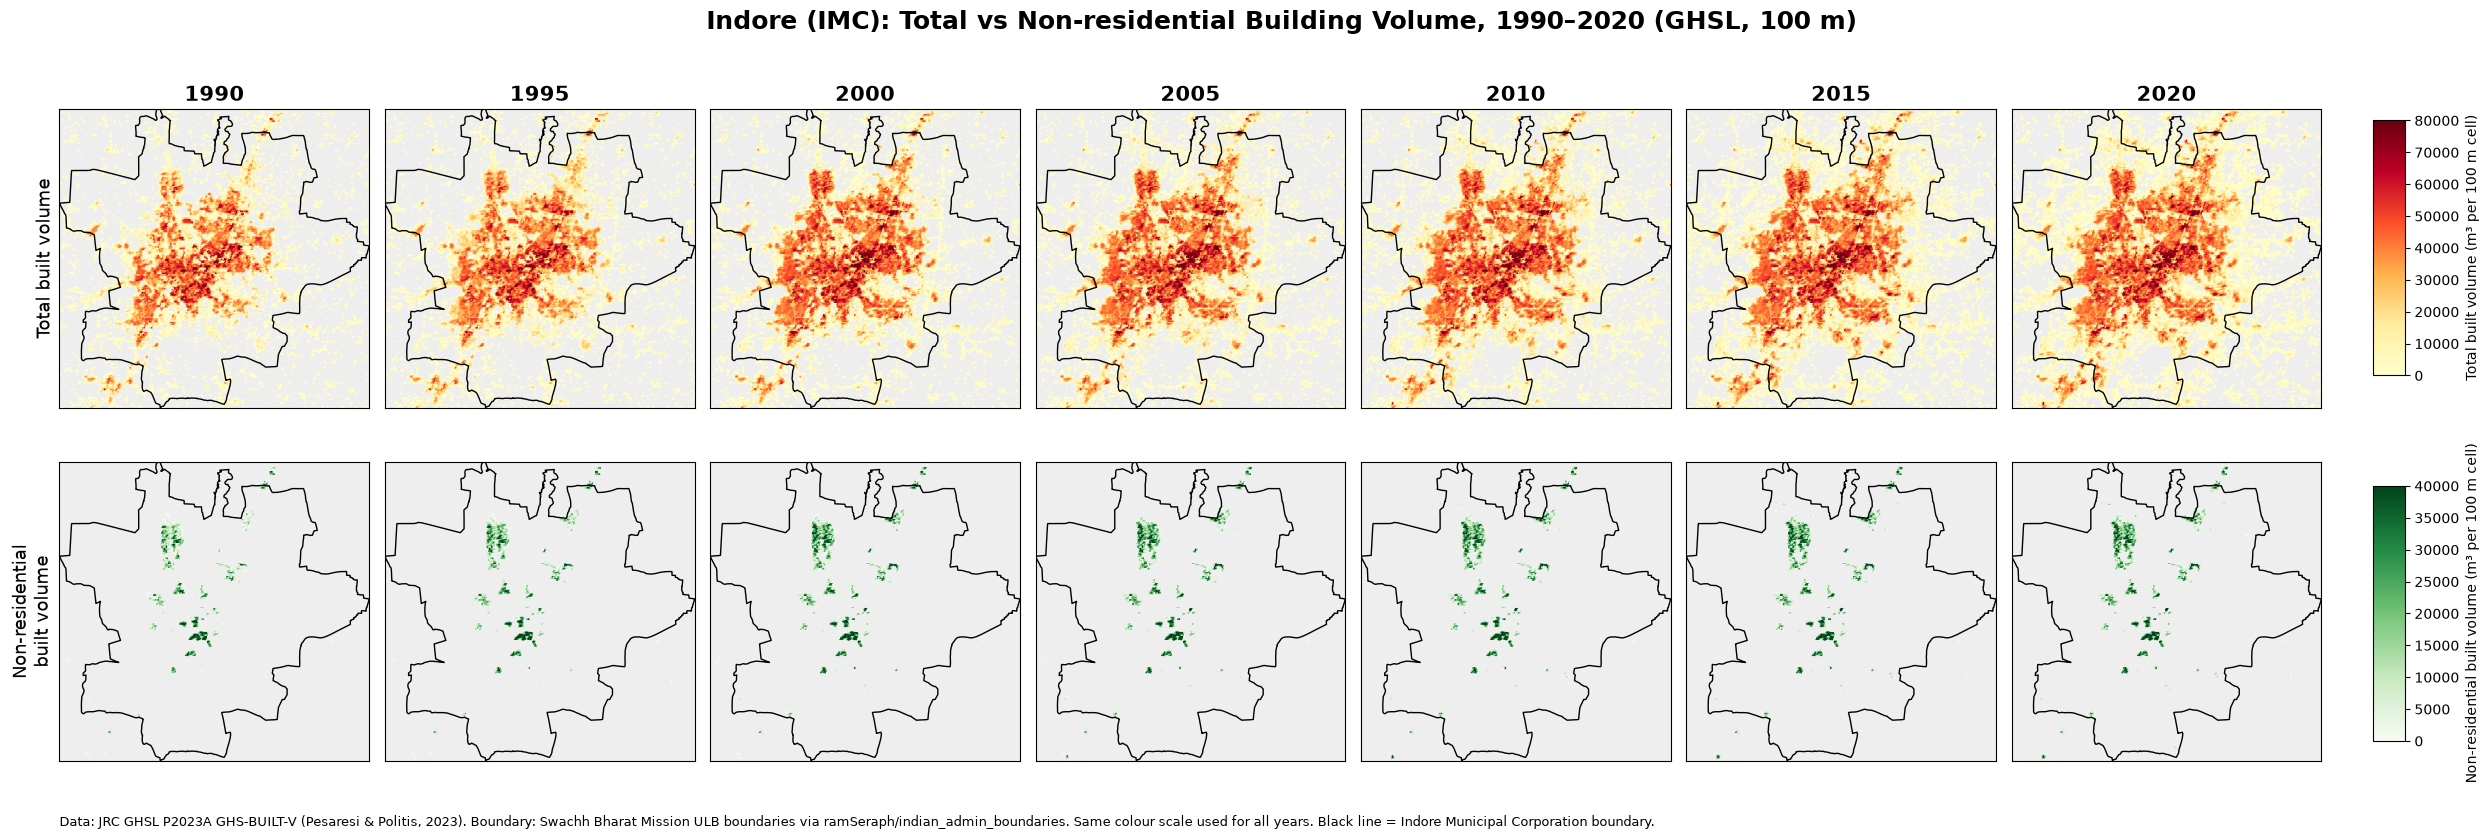

In [26]:
PAL_TOTAL = ["#ffffcc", "#ffeda0", "#feb24c", "#fc4e2a", "#bd0026", "#67000d"]
PAL_NRES  = ["#f7fcf5", "#c7e9c0", "#74c476", "#238b45", "#00441b"]

minx, miny, maxx, maxy = indore.total_bounds
region = ee.Geometry.Rectangle([minx, miny, maxx, maxy], None, False)
W = 420
H = int(W * (maxy - miny) / (maxx - minx))

def get_png(year, band, vmax, palette):
    img = col.filter(ee.Filter.eq("system:index", str(year))).first().select(band)
    vis = img.updateMask(img.gt(0)).visualize(min=0, max=vmax, palette=palette)
    url = vis.getThumbURL({"region": region, "dimensions": f"{W}x{H}",
                           "crs": "EPSG:4326", "format": "png"})
    r = requests.get(url, timeout=180)
    r.raise_for_status()
    return np.array(Image.open(io.BytesIO(r.content)).convert("RGBA"))

cmapT = LinearSegmentedColormap.from_list("t", PAL_TOTAL)
cmapN = LinearSegmentedColormap.from_list("n", PAL_NRES)

fig, axes = plt.subplots(2, 7, figsize=(26, 8.5))
for j, y in enumerate(years):
    for i, (band, vmax, pal) in enumerate([
        ("built_volume_total", VMAX_TOTAL, PAL_TOTAL),
        ("built_volume_nres",  VMAX_NRES,  PAL_NRES)]):
        ax = axes[i, j]
        ax.set_facecolor("#eeeeee")
        ax.imshow(get_png(y, band, vmax, pal), extent=[minx, maxx, miny, maxy], origin="upper")
        indore.boundary.plot(ax=ax, color="black", linewidth=1)
        ax.set_aspect(1 / math.cos(math.radians((miny + maxy) / 2)))
        ax.set_xticks([]); ax.set_yticks([])
        if i == 0:
            ax.set_title(str(y), fontsize=15, fontweight="bold")
axes[0, 0].set_ylabel("Total built volume", fontsize=13)
axes[1, 0].set_ylabel("Non-residential\nbuilt volume", fontsize=13)

fig.suptitle("Indore (IMC): Total vs Non-residential Building Volume, 1990–2020 (GHSL, 100 m)",
             fontsize=18, fontweight="bold")
fig.subplots_adjust(left=0.03, right=0.90, top=0.88, bottom=0.08, wspace=0.05, hspace=0.08)

cax1 = fig.add_axes([0.92, 0.55, 0.012, 0.30])
fig.colorbar(ScalarMappable(norm=Normalize(0, VMAX_TOTAL), cmap=cmapT), cax=cax1,
             label="Total built volume (m³ per 100 m cell)")
cax2 = fig.add_axes([0.92, 0.12, 0.012, 0.30])
fig.colorbar(ScalarMappable(norm=Normalize(0, VMAX_NRES), cmap=cmapN), cax=cax2,
             label="Non-residential built volume (m³ per 100 m cell)")

fig.text(0.03, 0.02,
         "Data: JRC GHSL P2023A GHS-BUILT-V (Pesaresi & Politis, 2023). Boundary: Swachh Bharat Mission ULB boundaries via "
         "ramSeraph/indian_admin_boundaries. Same colour scale used for all years. Black line = Indore Municipal Corporation boundary.",
         fontsize=9)
plt.savefig("indore_ghsl_total_vs_nres_maps.png", dpi=150, bbox_inches="tight")
plt.show()

## Step 9: Time-lapse GIF
Animated sequence (1990 → 2020) showing total and non-residential volume side by side, with yearly totals and non-residential share.

GIF saved: 1.02 MB


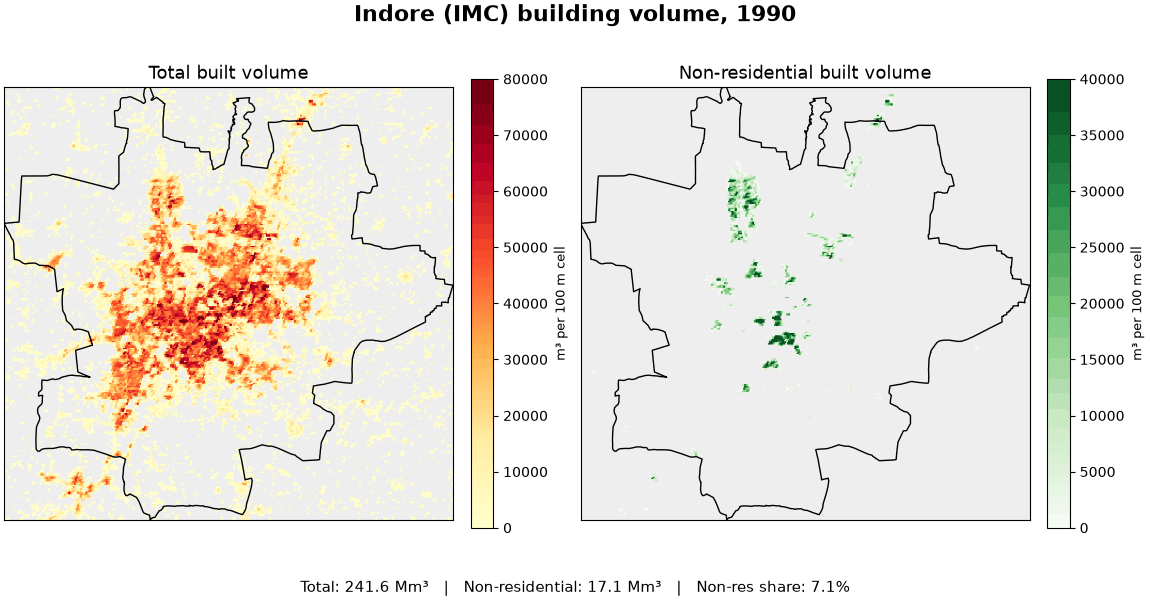

In [27]:
frames = []
for y in years:
    fig, axs = plt.subplots(1, 2, figsize=(11.5, 6), layout="constrained")
    for ax, band, cmap, vmax, ttl in [
        (axs[0], "built_volume_total", cmapT, VMAX_TOTAL, "Total built volume"),
        (axs[1], "built_volume_nres",  cmapN, VMAX_NRES,  "Non-residential built volume")]:
        ax.set_facecolor("#eeeeee")
        ax.imshow(get_png_cached(y, band), extent=[minx, maxx, miny, maxy], origin="upper")
        indore.boundary.plot(ax=ax, color="black", linewidth=1)
        ax.set_aspect(1 / math.cos(math.radians((miny + maxy) / 2)))
        ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(ttl, fontsize=13)
        cb = fig.colorbar(ScalarMappable(norm=Normalize(0, vmax), cmap=cmap),
                          ax=ax, fraction=0.05, pad=0.04)
        cb.set_label("m³ per 100 m cell", fontsize=9)

    row = stats[stats["year"] == y].iloc[0]
    fig.suptitle(f"Indore (IMC) building volume, {y}", fontsize=16, fontweight="bold")
    fig.supxlabel(f"Total: {row['total_Mm3']:.1f} Mm³   |   Non-residential: {row['nres_Mm3']:.1f} Mm³   |   "
                  f"Non-res share: {row['nres_share_%']:.1f}%", fontsize=11)

    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=100)
    plt.close(fig)
    buf.seek(0)
    frames.append(Image.open(buf).convert("RGB").copy())

frames[0].save("indore_ghsl_timelapse.gif", save_all=True, append_images=frames[1:],
               duration=1100, loop=0)
print("GIF saved:", round(os.path.getsize("indore_ghsl_timelapse.gif") / 1e6, 2), "MB")
IPImage(filename="indore_ghsl_timelapse.gif")

## Step 10: Total vs non-residential comparison charts
Absolute volumes, growth index (1990 = 100), and non-residential share of the total.

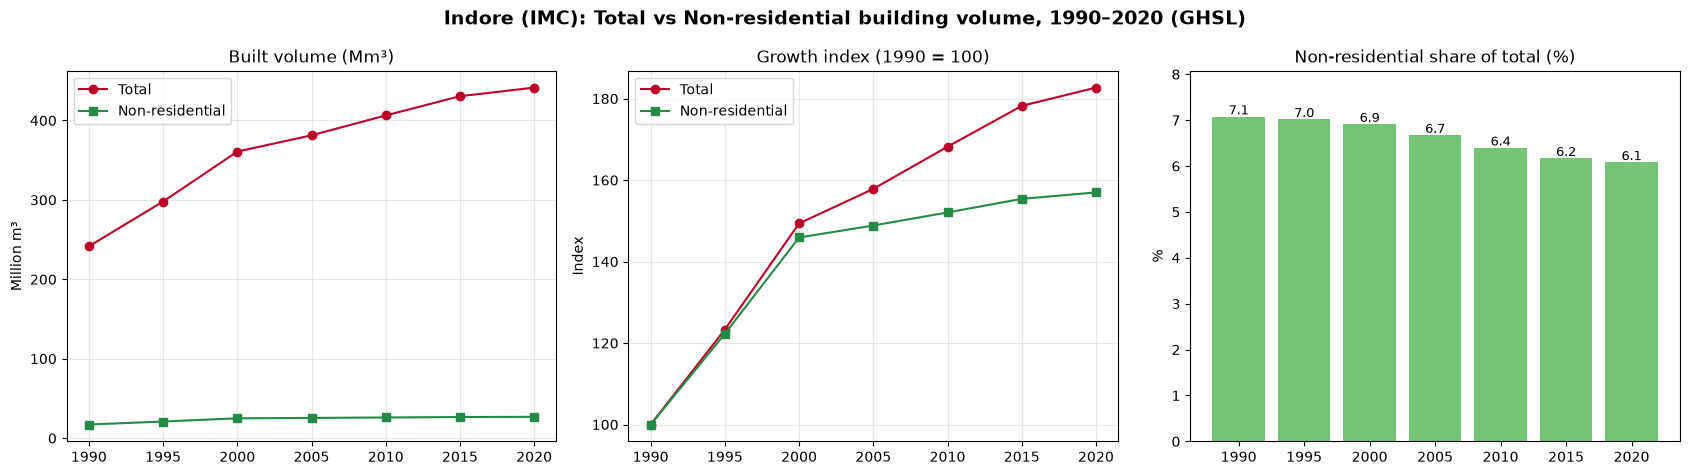

In [28]:
fig, axs = plt.subplots(1, 3, figsize=(17, 4.8))

# 1) Absolute volumes
axs[0].plot(stats["year"], stats["total_Mm3"], marker="o", color="#bd0026", label="Total")
axs[0].plot(stats["year"], stats["nres_Mm3"], marker="s", color="#238b45", label="Non-residential")
axs[0].set_title("Built volume (Mm³)"); axs[0].set_ylabel("Million m³")
axs[0].legend(); axs[0].grid(alpha=0.3)

# 2) Index (1990 = 100)
axs[1].plot(stats["year"], 100 * stats["total_m3"] / stats.loc[0, "total_m3"],
            marker="o", color="#bd0026", label="Total")
axs[1].plot(stats["year"], 100 * stats["nres_m3"] / stats.loc[0, "nres_m3"],
            marker="s", color="#238b45", label="Non-residential")
axs[1].set_title("Growth index (1990 = 100)"); axs[1].set_ylabel("Index")
axs[1].legend(); axs[1].grid(alpha=0.3)

# 3) Non-res share
axs[2].bar(stats["year"].astype(str), stats["nres_share_%"], color="#74c476")
for i, v in enumerate(stats["nres_share_%"]):
    axs[2].text(i, v + 0.05, f"{v:.1f}", ha="center", fontsize=9)
axs[2].set_title("Non-residential share of total (%)"); axs[2].set_ylabel("%")
axs[2].set_ylim(0, stats["nres_share_%"].max() + 1)

for a in axs[:2]:
    a.set_xticks(stats["year"])
fig.suptitle("Indore (IMC): Total vs Non-residential building volume, 1990–2020 (GHSL)",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("indore_ghsl_comparison_chart.png", dpi=150, bbox_inches="tight")
plt.show()

## Step 11: Build the web page
Assemble the interactive year slider, GIF, maps, summary table, charts, interpretation and limitations into a single `index.html` (images embedded), hosted on GitHub Pages.

In [29]:
import base64, io, json, os

def pil_b64(im):
    b = io.BytesIO(); im.save(b, format="PNG", optimize=True)
    return base64.b64encode(b.getvalue()).decode()

def file_b64(p):
    with open(p, "rb") as fh:
        return base64.b64encode(fh.read()).decode()

frame_b64 = [pil_b64(f) for f in frames]
gif_b64   = file_b64("indore_ghsl_timelapse.gif")
chart_b64 = file_b64("indore_ghsl_comparison_chart.png")
maps_b64  = file_b64("indore_ghsl_total_vs_nres_maps.png")

# ---- numbers for the text ----
t = stats.set_index("year")
tot90, tot00, tot20 = t.loc[1990, "total_Mm3"], t.loc[2000, "total_Mm3"], t.loc[2020, "total_Mm3"]
n90,   n00,   n20   = t.loc[1990, "nres_Mm3"],  t.loc[2000, "nres_Mm3"],  t.loc[2020, "nres_Mm3"]
tot_chg, n_chg = t.loc[2020, "total_chg_%_vs_1990"], t.loc[2020, "nres_chg_%_vs_1990"]
tot_chg00, n_chg00 = t.loc[2000, "total_chg_%_vs_1990"], t.loc[2000, "nres_chg_%_vs_1990"]
sh90, sh20 = t.loc[1990, "nres_share_%"], t.loc[2020, "nres_share_%"]
tot_0020 = 100 * (tot20 / tot00 - 1)
n_0020   = 100 * (n20 / n00 - 1)

tbl = stats[["year", "total_Mm3", "nres_Mm3", "res_Mm3", "nres_share_%",
             "total_chg_%_vs_1990", "nres_chg_%_vs_1990"]].round(2)
tbl.columns = ["Year", "Total (Mm³)", "Non-residential (Mm³)", "Residential = total − non-res (Mm³)",
               "Non-res share (%)", "Total change vs 1990 (%)", "Non-res change vs 1990 (%)"]
table_html = tbl.to_html(index=False, border=0)

interp_spatial = (
    "In 1990 the built volume of Indore (IMC) is concentrated in a compact, dense core, with a thin, low-volume "
    "fringe. By 2020 the core has intensified (more cells in the highest volume classes) and the moderately built "
    "fringe has spread outward in almost all directions, especially around the central and eastern parts of the city. "
    "Non-residential volume behaves differently: it occurs in a few discrete clusters (one large patch in the north "
    "and several smaller ones in the central/southern parts) rather than spreading across the whole city. "
    "Identifying what these clusters are (industrial, institutional, commercial) needs land-use data, which was not used here."
)
interp_temporal = (
    f"Total building volume within the municipal boundary rose from {tot90:.1f} Mm³ in 1990 to {tot20:.1f} Mm³ in 2020 "
    f"(+{tot_chg:.1f}%). Non-residential volume rose from {n90:.1f} to {n20:.1f} Mm³ (+{n_chg:.1f}%). "
    f"The fastest growth happened in 1990–2000 (total +{tot_chg00:.1f}%, non-residential +{n_chg00:.1f}%); after 2000 "
    f"growth slowed, but unevenly: between 2000 and 2020 total volume still grew by {tot_0020:.1f}%, whereas "
    f"non-residential volume grew by only {n_0020:.1f}%."
)
interp_compare = (
    f"Because total volume grew faster than non-residential volume, the non-residential share fell from "
    f"{sh90:.1f}% (1990) to {sh20:.1f}% (2020). Most of the volume added since 2000 is therefore residential or "
    f"other (total − non-residential), and the city has become slightly more residential in its built-up mix, "
    f"even though absolute non-residential volume kept increasing."
)

TEMPLATE = """<!doctype html>
<html lang="en"><head><meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>Indore Building Volume 1990-2020</title>
<style>
:root{--bg:#fafaf7;--card:#fff;--ink:#1d2330;--mute:#5d6676;--line:#e3e1d8;--acc:#bd0026;--grn:#238b45}
*{box-sizing:border-box}
body{margin:0;background:var(--bg);color:var(--ink);font-family:system-ui,-apple-system,Segoe UI,Roboto,sans-serif;line-height:1.6}
.wrap{max-width:1100px;margin:0 auto;padding:0 16px 48px}
header{padding:32px 0 8px}
h1{font-size:clamp(1.6rem,4vw,2.3rem);margin:0 0 6px;line-height:1.2}
.sub{color:var(--mute);margin:0}
h2{font-size:1.35rem;margin:40px 0 10px;border-bottom:2px solid var(--line);padding-bottom:6px}
.card{background:var(--card);border:1px solid var(--line);border-radius:10px;padding:16px}
.stats{display:grid;grid-template-columns:repeat(auto-fit,minmax(200px,1fr));gap:12px;margin:18px 0}
.stat b{display:block;font-size:1.7rem}
.stat span{color:var(--mute);font-size:.9rem}
img{max-width:100%;height:auto;display:block;margin:0 auto}
.ctl{display:flex;gap:12px;align-items:center;margin:10px 0}
.ctl input{flex:1}
.ctl button{padding:6px 14px;border:1px solid var(--line);background:#fff;border-radius:6px;cursor:pointer;font-size:1rem}
.yr{font-weight:700;font-size:1.3rem;min-width:3.5rem}
.tblwrap{overflow-x:auto}
table{border-collapse:collapse;width:100%;font-size:.92rem}
th,td{padding:7px 10px;border-bottom:1px solid var(--line);text-align:right;white-space:nowrap}
th{background:#f2f0e8;text-align:right}
ul{padding-left:20px}
small,.note{color:var(--mute);font-size:.88rem}
a{color:#0b5cad}
</style></head><body><div class="wrap">
<header>
<h1>Indore (IMC): Total vs Non-residential Building Volume, 1990–2020</h1>
<p class="sub">Urban Informatics and Spatial Analytics (HS524M), Test 2, Q2 &nbsp;|&nbsp; Manish Chouhan (CE25M108), M.Tech EWRE, IIT Tirupati</p>
</header>

<div class="stats">
<div class="card stat"><b>+__TOTCHG__%</b><span>Total building volume, 1990 → 2020 (__TOT90__ → __TOT20__ Mm³)</span></div>
<div class="card stat"><b>+__NCHG__%</b><span>Non-residential volume, 1990 → 2020 (__N90__ → __N20__ Mm³)</span></div>
<div class="card stat"><b>__SH90__% → __SH20__%</b><span>Non-residential share of total volume</span></div>
</div>

<h2>1. About this analysis</h2>
<div class="card"><p>This page compares the change in <b>total</b> and <b>non-residential</b> building volume inside the Indore Municipal Corporation
boundary between 1990 and 2020, in 5-year epochs, using the JRC GHSL built-up volume product (100 m grid; bands
<code>built_volume_total</code> and <code>built_volume_nres</code>, in m³ per 100 m cell). Values were processed in Google Earth Engine (Python API) and summed inside the city boundary.
All maps use one fixed colour scale for every year, so colours are directly comparable across years.</p></div>

<h2>2. Interactive time slider</h2>
<div class="card">
<div class="ctl"><button id="play">▶ Play</button><span class="yr" id="yr">1990</span>
<input type="range" id="slider" min="0" max="6" step="1" value="0" aria-label="Year"></div>
<img id="frameImg" alt="Total and non-residential building volume for the selected year">
</div>

<h2>3. Time-lapse (GIF)</h2>
<div class="card"><img alt="Animated GIF of building volume 1990-2020" src="data:image/gif;base64,__GIF__"></div>

<h2>4. All epochs side by side</h2>
<div class="card"><img alt="Maps of total and non-residential building volume for 1990-2020" src="data:image/png;base64,__MAPS__"></div>

<h2>5. Numerical summary</h2>
<div class="card tblwrap">__TABLE__</div>
<p class="note">Mm³ = million cubic metres, summed over all 100 m cells inside the boundary.</p>

<h2>6. Total vs non-residential comparison</h2>
<div class="card"><img alt="Comparison chart" src="data:image/png;base64,__CHART__"></div>

<h2>7. Interpretation</h2>
<div class="card">
<h3>Spatial pattern</h3><p>__SPATIAL__</p>
<h3>Temporal change</h3><p>__TEMPORAL__</p>
<h3>Total vs non-residential</h3><p>__COMPARE__</p>
</div>

<h2>8. Limitations</h2>
<div class="card"><ul>
<li><b>Resolution:</b> the grid is 100 m, so small buildings, narrow lanes and boundary cells are generalised; cells straddling the boundary are counted whole.</li>
<li><b>5-year epochs:</b> only snapshots every 5 years are available; changes within an epoch, and the exact timing of growth, cannot be resolved.</li>
<li><b>Modelled data:</b> built-up volume and the residential/non-residential split are derived (modelled) from satellite and ancillary data, not surveyed; errors in building height and use classification propagate into volumes.</li>
<li><b>Non-residential is a small share</b> (about 6–7%), so relative errors in this band are larger than for total volume.</li>
<li><b>"Residential" here is total − non-residential</b>, i.e. it may include other uses the product does not label as non-residential.</li>
<li><b>Boundary:</b> the municipal (ULB) boundary is administrative; growth outside it is not captured.</li>
</ul></div>

<h2>9. Data and sources</h2>
<div class="card"><ul>
<li>Building volume: Pesaresi, M., Politis, P. (2023). GHS-BUILT-V R2023A, GHS built-up volume grids derived from joint assessment of Sentinel-2, Landsat and global DEM data, multitemporal (1975–2030). European Commission, JRC. DOI: 10.2905/AB2F107A-03CD-47A3-85E5-139D8EC63283. Earth Engine asset: <code>JRC/GHSL/P2023A/GHS_BUILT_V</code>.</li>
<li>City boundary: Indore Municipal Corporation (IMC) polygon from the Swachh Bharat Mission ULB boundaries, accessed via <a href="https://github.com/ramSeraph/indian_admin_boundaries/releases/tag/urban">ramSeraph/indian_admin_boundaries (urban release)</a> (CC0 1.0).</li>
<li>Tools: Google Earth Engine (Python API), GeoPandas, Matplotlib, Pillow.</li>
</ul></div>
<p class="note">Prepared by Manish Chouhan (CE25M108) for HS524M Test 2.</p>

<script>
const frames = __FRAMES__;
const years = __YEARS__;
const img = document.getElementById('frameImg');
const lab = document.getElementById('yr');
const slider = document.getElementById('slider');
const btn = document.getElementById('play');
let timer = null;
function show(i){ img.src = 'data:image/png;base64,' + frames[i]; lab.textContent = years[i]; slider.value = i; }
slider.addEventListener('input', e => show(+e.target.value));
btn.addEventListener('click', () => {
  if (timer) { clearInterval(timer); timer = null; btn.textContent = '▶ Play'; return; }
  btn.textContent = '⏸ Pause';
  timer = setInterval(() => show((+slider.value + 1) % years.length), 1000);
});
show(0);
</script>
</div></body></html>"""

html = (TEMPLATE
    .replace("__FRAMES__", json.dumps(frame_b64))
    .replace("__YEARS__", json.dumps(years))
    .replace("__GIF__", gif_b64).replace("__MAPS__", maps_b64).replace("__CHART__", chart_b64)
    .replace("__TABLE__", table_html)
    .replace("__SPATIAL__", interp_spatial).replace("__TEMPORAL__", interp_temporal).replace("__COMPARE__", interp_compare)
    .replace("__TOTCHG__", f"{tot_chg:.1f}").replace("__NCHG__", f"{n_chg:.1f}")
    .replace("__TOT90__", f"{tot90:.1f}").replace("__TOT20__", f"{tot20:.1f}")
    .replace("__N90__", f"{n90:.1f}").replace("__N20__", f"{n20:.1f}")
    .replace("__SH90__", f"{sh90:.1f}").replace("__SH20__", f"{sh20:.1f}"))

os.makedirs("indore_site", exist_ok=True)
with open("indore_site/index.html", "w", encoding="utf-8") as fh:
    fh.write(html)
print("Saved indore_site/index.html |", round(os.path.getsize("indore_site/index.html") / 1e6, 1), "MB")

Saved indore_site/index.html | 7.0 MB
